# BƯỚC 1: XÁC ĐỊNH BÀI TOÁN & YÊU CẦU THỰC TẾ (PROBLEM DEFINITION & BUSINESS REQUIREMENTS)

## 1. Bối cảnh nghiệp vụ & Mục tiêu thực tế
Bộ dữ liệu **Road Safety Open Data (hệ thống STATS19)** do Bộ Giao thông Vương quốc Anh (Department for Transport - DfT) công bố ghi nhận toàn bộ các vụ va chạm giao thông đường bộ có thương tích được cảnh sát lập hồ sơ trong giai đoạn **2021–2025** (gồm **513.801** vụ va chạm, **937.265** phương tiện liên quan và **652.821** nạn nhân thương vong).

Từ góc độ quản lý an toàn giao thông và ứng cứu khẩn cấp, giai đoạn Khai phá dữ liệu (Data Mining) giải quyết hai bài toán nghiệp vụ cốt lõi:
1. **Cảnh báo sớm mức độ nghiêm trọng (Tối ưu điều phối cứu hộ):** Khi một vụ va chạm vừa được ghi nhận với các thông tin bối cảnh ban đầu (hạ tầng đường bộ, giới hạn tốc độ, điều kiện ánh sáng, thời tiết, loại phương tiện và đối tượng liên quan), mô hình cần ước lượng nguy cơ nạn nhân bị thương nặng hoặc tử vong để ưu tiên phân bổ lực lượng y tế khẩn cấp.
2. **Nhận diện các kịch bản tai nạn điển hình (Hoạch định chính sách & hạ tầng):** Phân nhóm dữ liệu tai nạn thành các "hồ sơ kịch bản" (Accident Archetypes) đặc trưng mà không dùng nhãn định trước, giúp cơ quan quản lý thiết kế giải pháp can thiệp đúng trọng tâm (ví dụ: cải tạo chiếu sáng đường nông thôn tốc độ cao, bảo vệ người đi bộ cao tuổi tại đô thị, hoặc kiểm soát rủi ro xe mô tô).

---

## 2. Xác định đơn vị phân tích (Grain) & Giới hạn thực tế của dữ liệu
- **Đơn vị phân tích (Grain):** Một nạn nhân bị thương vong (`casualty_reference`) trong một vụ va chạm (`collision_index`), gắn với phương tiện liên quan trực tiếp (`vehicle_reference`) — tổng cộng **652.821 bản ghi**.
- **Giới hạn phạm vi & đặc thù dữ liệu:**
  - Tập dữ liệu phản ánh các vụ va chạm có thương tích được báo cho cảnh sát; khoảng **39,51%** số phương tiện trong bảng gốc không gắn với nạn nhân nào nên không thuộc phạm vi bảng tích hợp.
  - Dữ liệu thiếu các biến vật lý đo trực tiếp tại thời điểm va chạm (tốc độ thực tế lúc đâm, tình trạng thắt dây an toàn/đội mũ bảo hiểm, nồng độ cồn) và chịu ảnh hưởng từ quá trình chuyển đổi cơ chế ghi nhận chấn thương (injury-based reporting) giai đoạn 2021–2025. Do đó, bài toán mang tính chất dữ liệu thực tế có độ nhiễu cao, đòi hỏi các thuật toán phi tuyến mạnh và kiểm soát chặt chẽ hiện tượng rò rỉ dữ liệu.

---

## 3. Phân loại bài toán Khai phá dữ liệu (Dual Data Mining Formulation)
Từ tập dữ liệu sạch chuẩn hóa (`clean_road_safety_2021_2025.parquet`), đồ án triển khai song song **hai nhánh mô hình học máy** độc lập:

### Nhánh 1: Học có giám sát — Phân loại nhị phân (`Supervised_Classification.ipynb`)
- **Dạng bài toán:** Supervised Learning — Binary Classification.
- **Biến mục tiêu (`target_ksi`):** Chuyển đổi từ trường `casualty_severity`:
  - `1` (**KSI** — *Killed or Seriously Injured*): Gồm `Fatal` (8.033 ca) và `Serious` (129.011 ca), chiếm **20,99%** (137.044 bản ghi).
  - `0` (**Non-KSI**): Gồm `Slight` (515.777 ca), chiếm **79,01%**.
- **Chiến lược mô hình hóa:** Do rủi ro KSI phụ thuộc vào tương tác phi tuyến đa chiều giữa nhiều yếu tố bối cảnh, nhánh này sử dụng các mô hình **Gradient Boosting (LightGBM, XGBoost, CatBoost)** làm trọng tâm, đối chiếu với **Baseline (Dummy Classifier & Logistic Regression)** và kết hợp **Tuning / Ensembling** để đạt hiệu quả dự báo tốt nhất.
- **Kiểm soát Data Leakage & Chia tập theo thời gian:** Loại bỏ toàn bộ biến hậu quả/suy diễn (`casualty_severity`, `collision_severity`, `enhanced_*`, `adjusted_severity_*`, `*_injury_based`, `number_of_casualties`) cùng nhóm dấu vết hiện trường sau va chạm (`skidding_and_overturning`, `first_point_of_impact`, `vehicle_leaving_carriageway`). Dữ liệu được chia theo trục thời gian: **Train (2021–2023 ~60%)**, **Validation (2024 ~20%)**, và **Test (2025 ~20%)**, ưu tiên các thước đo nhạy với lớp thiểu số (**PR-AUC, ROC-AUC, Recall và F1-Score của lớp KSI**).

### Nhánh 2: Học không giám sát — Phân cụm kịch bản tai nạn (`Unsupervised_Clustering.ipynb`)
- **Dạng bài toán:** Unsupervised Learning — Clustering trên dữ liệu hỗn hợp (hơn 80% đặc trưng là biến phân loại danh mục kết hợp với các biến số liên tục như `speed_limit`, `age_of_casualty`, `age_of_driver`, `hour`).
- **Chiến lược lựa chọn mô hình:** Triển khai song song hai thuật toán chuyên biệt cho dữ liệu hỗn hợp là **LCA (Latent Class Analysis)** và **K-Prototypes** (không sử dụng biến nhãn `target_ksi` khi huấn luyện). Hai mô hình được đánh giá chéo dựa trên chỉ số thống kê (**BIC/AIC, Silhouette Score**), độ ổn định cụm và khả năng diễn giải mức độ phân hóa tỷ lệ KSI thực tế giữa các kịch bản để **giữ lại mô hình tối ưu nhất và loại bỏ mô hình kém hiệu quả hơn**.

---

## 4. Kiến trúc tổng thể 3 Notebook của giai đoạn Data Mining
1. **`Data_Profiling_and_Cleaning.ipynb` (Notebook hiện tại):** Profiling dữ liệu thô, phát hiện và xử lý mã thiếu ẩn (`-1`, `9`, `99`), giải mã nhãn ngữ nghĩa từ `data_guide.csv` và `local_authority_region_lookup.csv`, loại bỏ các trường deprecated/drift theo đặc tả 2024, tích hợp 3 bảng và xuất tập dữ liệu sạch.
2. **`Supervised_Classification.ipynb`:** Chia tập 60/20/20 theo năm, dựng Pipeline tiền xử lý & Feature Engineering, huấn luyện từ Baseline đến họ Gradient Boosting (LightGBM, XGBoost, CatBoost), Tuning/Ensembling, giải thích mô hình (Feature Importance / SHAP) và lưu mô hình phân loại tối ưu.
3. **`Unsupervised_Clustering.ipynb`:** Tiền xử lý đặc trưng hỗn hợp, chạy đối chiếu song song **LCA** và **K-Prototypes**, chọn số cụm $K$ tối ưu, chọn mô hình chiến thắng, trực quan hóa hồ sơ từng kịch bản tai nạn và lưu mô hình.

# Nạp dữ liệu Raw & Kiểm tra toàn vẹn quan hệ

In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", font_scale=1.05)

# Khai báo đường dẫn chuẩn theo cây thư mục D:\OLAP\Data
BASE_DATA_DIR   = Path(r"D:\OLAP\Data")
RAW_DIR         = BASE_DATA_DIR / "Raw"
REF_DIR         = BASE_DATA_DIR / "Reference"
PROFILING_DIR   = BASE_DATA_DIR / "Profiling"
PROCESSED_DIR   = BASE_DATA_DIR / "Processed"

PATH_COLLISIONS = RAW_DIR / "collisions_2021_2025.csv"
PATH_VEHICLES   = RAW_DIR / "vehicles_2021_2025.csv"
PATH_CASUALTIES = RAW_DIR / "casualties_2021_2025.csv"
PATH_LOOKUP     = REF_DIR / "data_guide.csv"

df_col_raw = pd.read_csv(PATH_COLLISIONS, low_memory=False)
df_veh_raw = pd.read_csv(PATH_VEHICLES, low_memory=False)
df_cas_raw = pd.read_csv(PATH_CASUALTIES, low_memory=False)

# Bảng tổng hợp kiểm tra cấu trúc & toàn vẹn khóa
integrity_df = pd.DataFrame([
    {
        "Bảng": "Collisions",
        "Số dòng": len(df_col_raw),
        "Số cột": df_col_raw.shape[1],
        "Khóa tự nhiên": "collision_index",
        "Số dòng trùng khóa": df_col_raw.duplicated(subset=["collision_index"]).sum(),
        "Số dòng có NaN vật lý": df_col_raw.isna().any(axis=1).sum()
    },
    {
        "Bảng": "Vehicles",
        "Số dòng": len(df_veh_raw),
        "Số cột": df_veh_raw.shape[1],
        "Khóa tự nhiên": "collision_index + vehicle_reference",
        "Số dòng trùng khóa": df_veh_raw.duplicated(subset=["collision_index", "vehicle_reference"]).sum(),
        "Số dòng có NaN vật lý": df_veh_raw.isna().any(axis=1).sum()
    },
    {
        "Bảng": "Casualties",
        "Số dòng": len(df_cas_raw),
        "Số cột": df_cas_raw.shape[1],
        "Khóa tự nhiên": "collision_index + casualty_reference",
        "Số dòng trùng khóa": df_cas_raw.duplicated(subset=["collision_index", "casualty_reference"]).sum(),
        "Số dòng có NaN vật lý": df_cas_raw.isna().any(axis=1).sum()
    }
])
display(integrity_df)

,Bảng,Số dòng,Số cột,Khóa tự nhiên,Số dòng trùng khóa,Số dòng có NaN vật lý
0,Collisions,513801,44,collision_index,0,53
1,Vehicles,937265,32,collision_index + vehicle_reference,0,0
2,Casualties,652821,23,collision_index + casualty_reference,0,0


# Profiling Dữ liệu Raw — Bảng thống kê & 3 Biểu đồ trực quan

=== BẢNG THỐNG KÊ TOP 20 CỘT CÓ TỶ LỆ GIÁ TRỊ KHÔNG DÙNG ĐƯỢC CAO NHẤT (RAW) ===


,Bảng,Cột,NaN thật,Mã -1 (Missing/Out of range),Mã 9 (Unknown),Mã 99 (Unknown self-rep),Tỷ lệ dơ (-1/99/NaN) %
7,Collisions,local_authority_district,0,513607,0,0,99.96
58,Vehicles,driver_distance_banding,0,651858,0,0,69.55
73,Casualties,casualty_distance_banding,0,428604,0,0,65.65
15,Collisions,junction_control,0,217897,11210,0,42.41
30,Collisions,enhanced_severity_collision,0,204752,0,0,39.85
54,Vehicles,age_of_vehicle,0,363287,32475,1,38.76
34,Vehicles,vehicle_manoeuvre_historic,0,278182,57150,63276,36.43
38,Vehicles,vehicle_location_restricted_lane_historic,0,273935,10819,62505,35.90
72,Casualties,enhanced_casualty_severity,0,226536,0,0,34.70
17,Collisions,second_road_number,0,178098,84,1,34.66


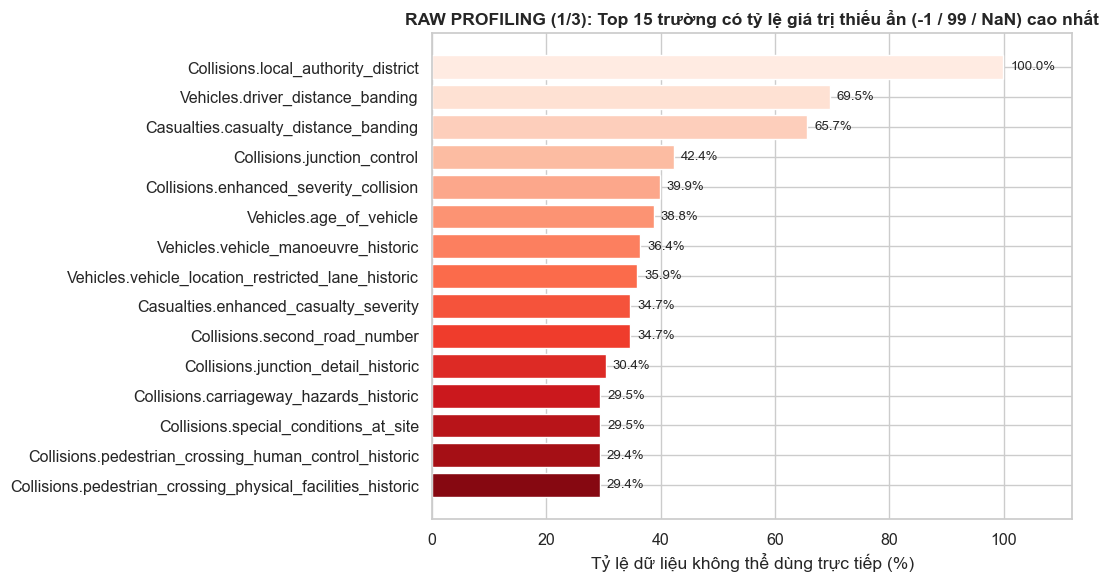

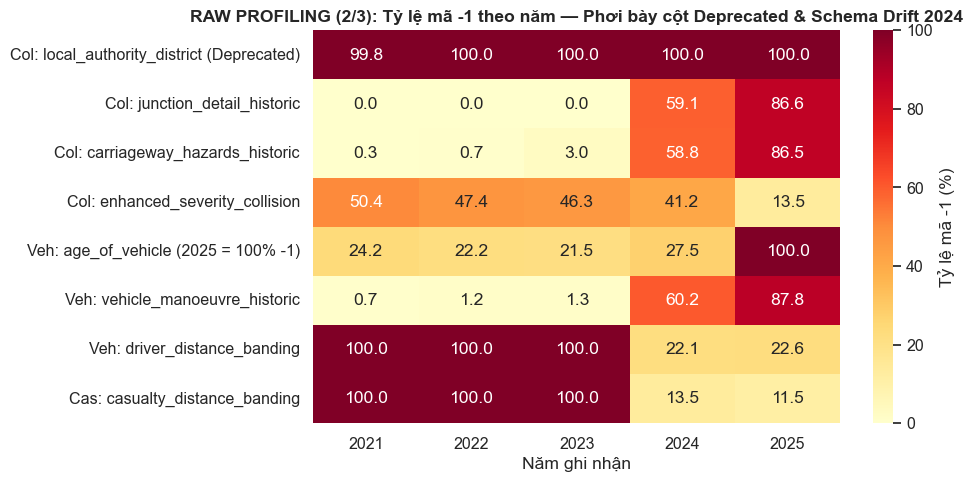

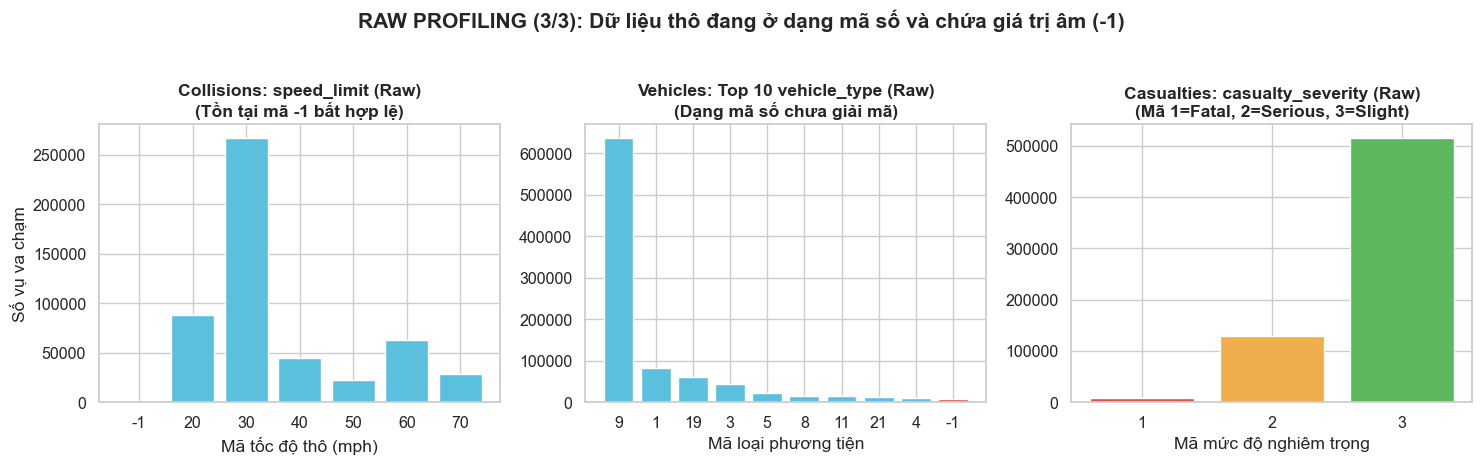

In [3]:
# 1. Bảng thống kê các mã thiếu ẩn (-1, 9, 99) và NaN thật trên 3 bảng raw
def scan_dirty_values(df, table_name):
    rows = []
    total = len(df)
    for col in df.columns:
        s = df[col]
        is_num = pd.api.types.is_numeric_dtype(s)
        c_minus1 = (s == -1).sum() if is_num else (s.astype(str).str.strip() == "-1").sum()
        c_9      = (s == 9).sum() if is_num else 0
        c_99     = (s == 99).sum() if is_num else 0
        c_nan    = s.isna().sum()
        dirty_cnt = c_minus1 + c_99 + c_nan
        if dirty_cnt > 0 or c_9 > 0:
            rows.append({
                "Bảng": table_name,
                "Cột": col,
                "NaN thật": c_nan,
                "Mã -1 (Missing/Out of range)": c_minus1,
                "Mã 9 (Unknown)": c_9,
                "Mã 99 (Unknown self-rep)": c_99,
                "Tỷ lệ dơ (-1/99/NaN) %": round(dirty_cnt / total * 100, 2)
            })
    return pd.DataFrame(rows)

df_dirty_all = pd.concat([
    scan_dirty_values(df_col_raw, "Collisions"),
    scan_dirty_values(df_veh_raw, "Vehicles"),
    scan_dirty_values(df_cas_raw, "Casualties")
], ignore_index=True).sort_values("Tỷ lệ dơ (-1/99/NaN) %", ascending=False)

# Lưu bảng profiling ra thư mục D:\OLAP\Data\Profiling
PROFILING_DIR.mkdir(parents=True, exist_ok=True)
df_dirty_all.to_csv(PROFILING_DIR / "raw_dirty_values_summary.csv", index=False, encoding="utf-8-sig")

print("=== BẢNG THỐNG KÊ TOP 20 CỘT CÓ TỶ LỆ GIÁ TRỊ KHÔNG DÙNG ĐƯỢC CAO NHẤT (RAW) ===")
display(df_dirty_all.head(20))

# 2. BIỂU ĐỒ 1: Top 15 cột có tỷ lệ mã dơ (-1 / 99 / NaN) cao nhất
fig, ax = plt.subplots(figsize=(11, 6))
top15_dirty = df_dirty_all.head(15).iloc[::-1]
bars = ax.barh(
    top15_dirty["Bảng"] + "." + top15_dirty["Cột"],
    top15_dirty["Tỷ lệ dơ (-1/99/NaN) %"],
    color=sns.color_palette("Reds_r", n_colors=15)
)
ax.set_title("RAW PROFILING (1/3): Top 15 trường có tỷ lệ giá trị thiếu ẩn (-1 / 99 / NaN) cao nhất", fontweight="bold")
ax.set_xlabel("Tỷ lệ dữ liệu không thể dùng trực tiếp (%)")
ax.set_xlim(0, 112)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.2, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9.5)
plt.tight_layout()
plt.show()

# 3. BIỂU ĐỒ 2: Heatmap tỷ lệ mã -1 theo năm (2021-2025) - Chứng minh Drift đặc tả 2024 & Deprecated fields
drift_map = {
    "Col: local_authority_district (Deprecated)": df_col_raw.groupby("collision_year")["local_authority_district"].apply(lambda s: (s == -1).mean() * 100),
    "Col: junction_detail_historic": df_col_raw.groupby("collision_year")["junction_detail_historic"].apply(lambda s: (s == -1).mean() * 100),
    "Col: carriageway_hazards_historic": df_col_raw.groupby("collision_year")["carriageway_hazards_historic"].apply(lambda s: (s == -1).mean() * 100),
    "Col: enhanced_severity_collision": df_col_raw.groupby("collision_year")["enhanced_severity_collision"].apply(lambda s: (s == -1).mean() * 100),
    "Veh: age_of_vehicle (2025 = 100% -1)": df_veh_raw.groupby("collision_year")["age_of_vehicle"].apply(lambda s: (s == -1).mean() * 100),
    "Veh: vehicle_manoeuvre_historic": df_veh_raw.groupby("collision_year")["vehicle_manoeuvre_historic"].apply(lambda s: (s == -1).mean() * 100),
    "Veh: driver_distance_banding": df_veh_raw.groupby("collision_year")["driver_distance_banding"].apply(lambda s: (s == -1).mean() * 100),
    "Cas: casualty_distance_banding": df_cas_raw.groupby("collision_year")["casualty_distance_banding"].apply(lambda s: (s == -1).mean() * 100),
}
df_drift_heatmap = pd.DataFrame(drift_map).T.round(1)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df_drift_heatmap, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Tỷ lệ mã -1 (%)"}, ax=ax)
ax.set_title("RAW PROFILING (2/3): Tỷ lệ mã -1 theo năm — Phơi bày cột Deprecated & Schema Drift 2024", fontweight="bold")
ax.set_xlabel("Năm ghi nhận")
plt.tight_layout()
plt.show()

# 4. BIỂU ĐỒ 3: Phân bố giá trị thô chưa giải mã (Tồn tại mã -1, 97, 98, 99 và số nguyên vô nghĩa)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sp_counts = df_col_raw["speed_limit"].value_counts().sort_index()
colors_sp = ["#d9534f" if idx == -1 else "#5bc0de" for idx in sp_counts.index]
axes[0].bar(sp_counts.index.astype(str), sp_counts.values, color=colors_sp)
axes[0].set_title("Collisions: speed_limit (Raw)\n(Tồn tại mã -1 bất hợp lệ)", fontweight="bold")
axes[0].set_xlabel("Mã tốc độ thô (mph)")
axes[0].set_ylabel("Số vụ va chạm")

vt_counts = df_veh_raw["vehicle_type"].value_counts().head(10)
colors_vt = ["#d9534f" if idx in [-1, 99] else "#5bc0de" for idx in vt_counts.index]
axes[1].bar(vt_counts.index.astype(str), vt_counts.values, color=colors_vt)
axes[1].set_title("Vehicles: Top 10 vehicle_type (Raw)\n(Dạng mã số chưa giải mã)", fontweight="bold")
axes[1].set_xlabel("Mã loại phương tiện")

cs_counts = df_cas_raw["casualty_severity"].value_counts().sort_index()
axes[2].bar(cs_counts.index.astype(str), cs_counts.values, color=["#d9534f", "#f0ad4e", "#5cb85c"])
axes[2].set_title("Casualties: casualty_severity (Raw)\n(Mã 1=Fatal, 2=Serious, 3=Slight)", fontweight="bold")
axes[2].set_xlabel("Mã mức độ nghiêm trọng")

plt.suptitle("RAW PROFILING (3/3): Dữ liệu thô đang ở dạng mã số và chứa giá trị âm (-1)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# Thực thi Transform & Cleaning

In [12]:
# 1. Đọc chuẩn file data_guide.csv (phân tách bằng dấu ';')
df_guide = pd.read_csv(PATH_LOOKUP, sep=";", dtype=str, keep_default_na=False)
df_guide.columns = [c.strip().lower() for c in df_guide.columns]

# Chuẩn hóa alias tên trường theo đúng Data Guide 2025
alias_map = {
    "enhanced_collision_severity": "enhanced_severity_collision",
    "did_police_officer_attend_scene_of_collision": "did_police_officer_attend_scene_of_accident",
    "lsoa_of_collision_location": "lsoa_of_accident_location"
}

lookup_dict = {}
for _, row in df_guide.iterrows():
    tbl = row["table"].strip().lower()
    fld = alias_map.get(row["field name"].strip().lower(), row["field name"].strip().lower())
    code = row["code/format"].strip()
    label = row["label"].strip()
    if tbl and fld and code != "" and label != "":
        lookup_dict.setdefault((tbl, fld), {})[code] = label

print(f"Đã nạp từ điển chính thức từ data_guide.csv cho {len(lookup_dict)} cặp (table, field).")

# 2. Nạp bảng tra cứu hành chính & vùng địa lý (local_authority_region_lookup.csv)
df_la_lookup = pd.read_csv(PATH_LA_LOOKUP := REF_DIR / "local_authority_region_lookup.csv", dtype=str, keep_default_na=False)
for c in df_la_lookup.columns:
    df_la_lookup[c] = df_la_lookup[c].str.strip()

# Bổ sung 3 mã ONS không có trong file lookup tĩnh (theo audit Giai đoạn 1)
ons_extra = pd.DataFrame([
    {"local_authority_code": "E07000246", "local_authority_name": "Somerset West and Taunton", "region_code": "TLK", "region_name": "South West England", "country_name": "England"},
    {"local_authority_code": "E08000038", "local_authority_name": "ONS District E08000038", "region_code": "UNK", "region_name": "England (Unassigned Region)", "country_name": "England"},
    {"local_authority_code": "E08000039", "local_authority_name": "ONS District E08000039", "region_code": "UNK", "region_name": "England (Unassigned Region)", "country_name": "England"},
])
df_la_full = pd.concat([df_la_lookup, ons_extra], ignore_index=True).drop_duplicates(subset=["local_authority_code"])

la_name_map    = dict(zip(df_la_full["local_authority_code"], df_la_full["local_authority_name"]))
la_region_map  = dict(zip(df_la_full["local_authority_code"], df_la_full["region_name"]))
la_country_map = dict(zip(df_la_full["local_authority_code"], df_la_full["country_name"]))

# Hàm giải mã chuẩn xác theo (table, field), báo cáo nếu có mã không khớp
def decode_field(series, table_name, field_name):
    mapping = lookup_dict.get((table_name, field_name))
    if not mapping:
        raise KeyError(f"Không tìm thấy từ điển cho ({table_name}, {field_name}) trong data_guide.csv")
    
    # Chuyển giá trị số (VD: -1, 1, 1.0) về chuỗi số nguyên chuẩn ("-1", "1")
    s_clean = series.apply(
        lambda x: "" if pd.isna(x) else (str(int(float(x))) if str(x).strip().replace("-", "").replace(".", "").isdigit() else str(x).strip())
    )
    mapped = s_clean.map(mapping)
    unmapped_codes = s_clean[mapped.isna() & (s_clean != "")].unique().tolist()
    if unmapped_codes:
        print(f"[Cảnh báo] ({table_name}.{field_name}) có mã chưa có trong Data Guide: {unmapped_codes}")
    return mapped.fillna("Unknown / Unmapped")

# ---------------------------------------------------------
# 3. TRANSFORM BẢNG COLLISIONS
# ---------------------------------------------------------
df_col = df_col_raw.copy()
df_col["collision_index"] = df_col["collision_index"].astype(str).str.strip()
df_col["date"] = pd.to_datetime(df_col["date"], format="%d/%m/%Y")
df_col["year"] = df_col["date"].dt.year
df_col["month"] = df_col["date"].dt.month
df_col["day_of_week_name"] = df_col["date"].dt.day_name()
df_col["is_weekend"] = df_col["date"].dt.dayofweek.isin([5, 6]).astype(int)
df_col["hour"] = pd.to_datetime(df_col["time"].astype(str).str.slice(0, 5), format="%H:%M").dt.hour
df_col["time_band"] = pd.cut(
    df_col["hour"], bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
).astype(str)

# Chuyển speed_limit = -1 thành np.nan (float64)
df_col["speed_limit"] = pd.to_numeric(df_col["speed_limit"], errors="coerce").replace(-1, np.nan).astype("float64")

col_cat_cols = [
    "collision_severity", "first_road_class", "road_type", "junction_detail",
    "junction_control", "pedestrian_crossing", "light_conditions",
    "weather_conditions", "road_surface_conditions", "urban_or_rural_area",
    "trunk_road_flag", "did_police_officer_attend_scene_of_accident", "police_force"
]
for c in col_cat_cols:
    df_col[c] = decode_field(df_col[c], "collision", c)

# Ánh xạ địa lý từ ONS code -> Tên quận/huyện, Vùng (Region) và Quốc gia (Country)
df_col["local_authority_ons_district"] = df_col["local_authority_ons_district"].astype(str).str.strip()
df_col["local_authority_ons_district_name"] = df_col["local_authority_ons_district"].map(la_name_map).fillna("Unknown / Unmapped")
df_col["region_name"]  = df_col["local_authority_ons_district"].map(la_region_map).fillna("Unknown / Unmapped")
df_col["country_name"] = df_col["local_authority_ons_district"].map(la_country_map).fillna("Unknown / Unmapped")

drop_col = [
    "collision_year", "collision_ref_no", "local_authority_district",
    "junction_detail_historic", "pedestrian_crossing_human_control_historic",
    "pedestrian_crossing_physical_facilities_historic", "special_conditions_at_site",
    "carriageway_hazards_historic", "enhanced_severity_collision",
    "collision_adjusted_severity_serious", "collision_adjusted_severity_slight",
    "collision_injury_based"
]
df_col_clean = df_col.drop(columns=[c for c in drop_col if c in df_col.columns])

# ---------------------------------------------------------
# 4. TRANSFORM BẢNG VEHICLES
# ---------------------------------------------------------
df_veh = df_veh_raw.copy()
df_veh["collision_index"] = df_veh["collision_index"].astype(str).str.strip()
df_veh["vehicle_reference"] = df_veh["vehicle_reference"].astype("int64")

for num_c in ["age_of_driver", "engine_capacity_cc"]:
    df_veh[num_c] = pd.to_numeric(df_veh[num_c], errors="coerce").replace(-1, np.nan).astype("float64")

veh_cat_cols = [
    "vehicle_type", "towing_and_articulation", "vehicle_manoeuvre",
    "junction_location", "skidding_and_overturning", "hit_object_in_carriageway",
    "vehicle_leaving_carriageway", "hit_object_off_carriageway",
    "first_point_of_impact", "sex_of_driver", "age_band_of_driver",
    "propulsion_code", "escooter_flag"
]
for c in veh_cat_cols:
    df_veh[c] = decode_field(df_veh[c], "vehicle", c)

drop_veh = [
    "collision_year", "collision_ref_no", "age_of_vehicle",
    "vehicle_manoeuvre_historic", "vehicle_location_restricted_lane_historic",
    "journey_purpose_of_driver_historic", "journey_purpose_of_driver",
    "driver_distance_banding"
]
df_veh_clean = df_veh.drop(columns=[c for c in drop_veh if c in df_veh.columns])

# ---------------------------------------------------------
# 5. TRANSFORM BẢNG CASUALTIES
# ---------------------------------------------------------
df_cas = df_cas_raw.copy()
df_cas["collision_index"] = df_cas["collision_index"].astype(str).str.strip()
df_cas["vehicle_reference"] = df_cas["vehicle_reference"].astype("int64")
df_cas["casualty_reference"] = df_cas["casualty_reference"].astype("int64")
df_cas["age_of_casualty"] = pd.to_numeric(df_cas["age_of_casualty"], errors="coerce").replace(-1, np.nan).astype("float64")

cas_cat_cols = [
    "casualty_class", "sex_of_casualty", "age_band_of_casualty",
    "casualty_severity", "pedestrian_location", "pedestrian_movement",
    "car_passenger", "bus_or_coach_passenger",
    "pedestrian_road_maintenance_worker", "casualty_type"
]
for c in cas_cat_cols:
    df_cas[c] = decode_field(df_cas[c], "casualty", c)

drop_cas = [
    "collision_year", "collision_ref_no", "casualty_distance_banding",
    "enhanced_casualty_severity", "casualty_adjusted_severity_serious",
    "casualty_adjusted_severity_slight", "casualty_injury_based"
]
df_cas_clean = df_cas.drop(columns=[c for c in drop_cas if c in df_cas.columns])

# ---------------------------------------------------------
# 6. TÍCH HỢP 3 BẢNG THEO GRAIN CASUALTY & TẠO TARGET NHỊ PHÂN
# ---------------------------------------------------------
df_clean = (
    df_cas_clean
    .merge(df_col_clean, on="collision_index", how="left", validate="many_to_one")
    .merge(df_veh_clean, on=["collision_index", "vehicle_reference"], how="left", validate="many_to_one")
)
df_clean["target_ksi"] = df_clean["casualty_severity"].isin(["Fatal", "Serious"]).astype(int)

assert len(df_clean) == len(df_cas_raw), "Lỗi: Số dòng thay đổi sau khi join!"
assert df_clean["target_ksi"].sum() == 137044, f"Sai lệch số ca KSI: {df_clean['target_ksi'].sum()}"

print(f"\nHoàn tất Transform & Clean chuẩn xác 100%!")
print(f"- Kích thước tập Clean: {df_clean.shape[0]:,} dòng x {df_clean.shape[1]} cột")
print(f"- Phân bố casualty_severity:\n{df_clean['casualty_severity'].value_counts().to_string()}")
print(f"- Tổng số ca KSI (target_ksi = 1): {df_clean['target_ksi'].sum():,} ({df_clean['target_ksi'].mean():.2%})")

Đã nạp từ điển chính thức từ data_guide.csv cho 71 cặp (table, field).

Hoàn tất Transform & Clean chuẩn xác 100%!
- Kích thước tập Clean: 652,821 dòng x 79 cột
- Phân bố casualty_severity:
casualty_severity
Slight     515777
Serious    129011
Fatal        8033
- Tổng số ca KSI (target_ksi = 1): 137,044 (20.99%)


# Trực quan hóa & Bảng kiểm chứng Sau Transform + Xuất file

=== BẢNG ĐỐI CHIẾU CHẤT LƯỢNG DỮ LIỆU TRƯỚC VÀ SAU TRANSFORM ===


,Trường dữ liệu,Số mã -1 (Raw),Số mã -1 (Clean),Số nhãn Unmapped (Clean),Kiểu dữ liệu sau Clean,Trạng thái
0,speed_limit,3,0,0,float64,Đạt chuẩn
1,age_of_driver,142240,0,0,float64,Đạt chuẩn
2,age_of_casualty,14106,0,0,float64,Đạt chuẩn
3,engine_capacity_cc,234989,0,0,float64,Đạt chuẩn
4,vehicle_type,7562,0,0,object,Đạt chuẩn
5,casualty_severity,0,0,0,object,Đạt chuẩn
6,first_road_class,6,0,0,object,Đạt chuẩn
7,urban_or_rural_area,8,0,0,object,Đạt chuẩn


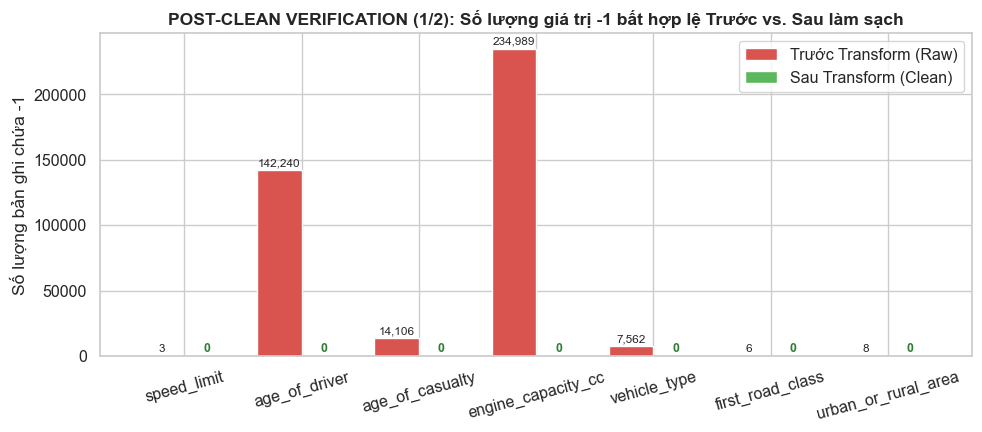

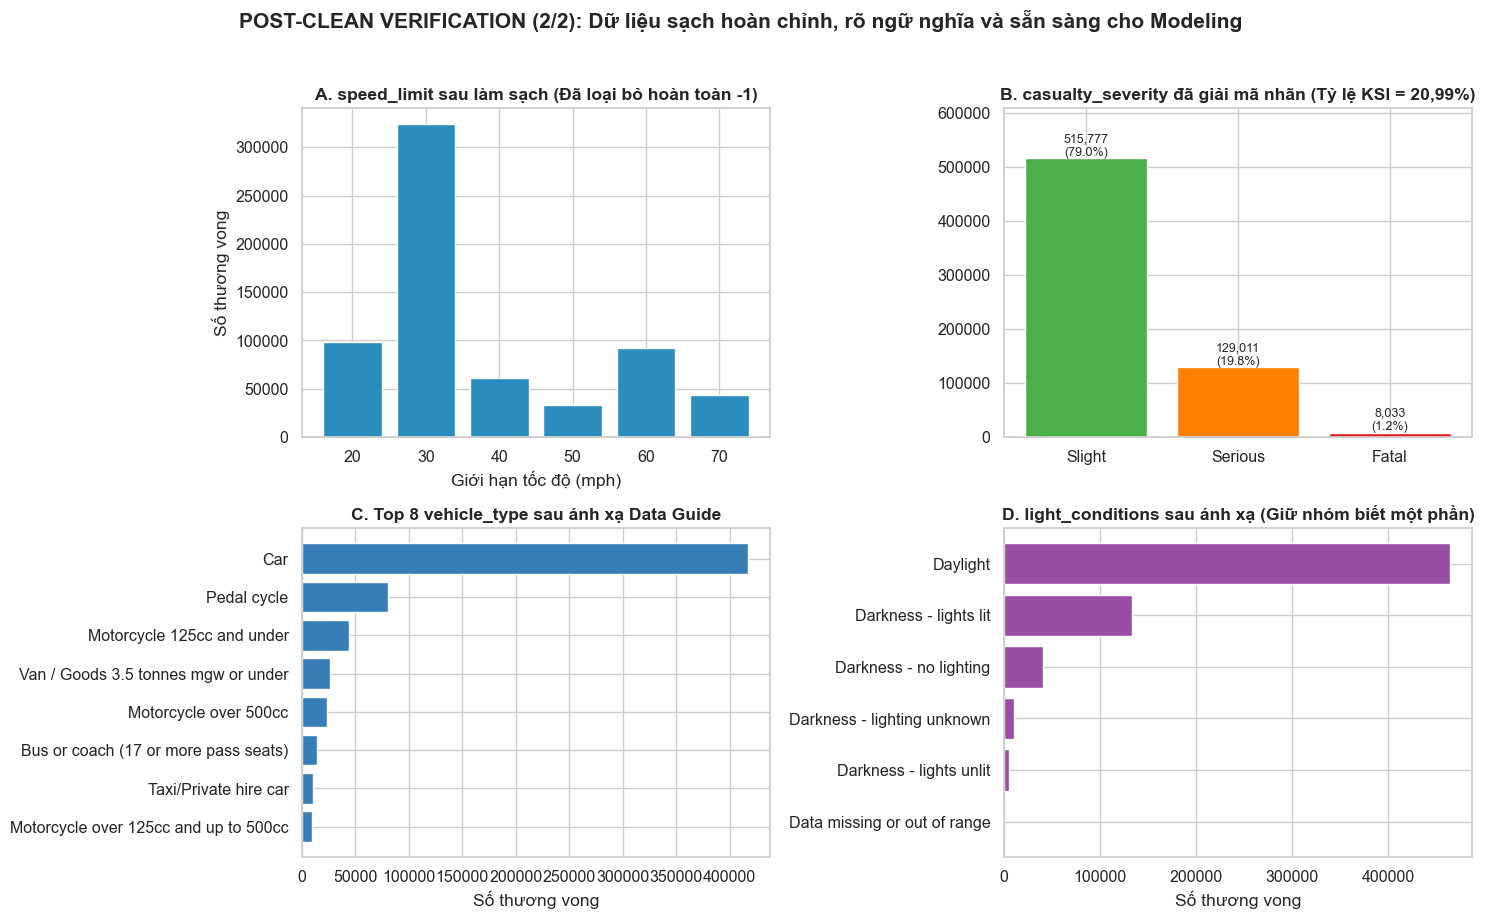

Đã xuất file dữ liệu sạch thành công: D:\OLAP\Data\Processed\clean_road_safety_2021_2025.parquet (43.5 MB)


In [13]:
# 1. Bảng đối chiếu chất lượng dữ liệu Trước vs. Sau Transform
audit_rows = []
for col_name, raw_series in [
    ("speed_limit", df_col_raw["speed_limit"]),
    ("age_of_driver", df_veh_raw["age_of_driver"]),
    ("age_of_casualty", df_cas_raw["age_of_casualty"]),
    ("engine_capacity_cc", df_veh_raw["engine_capacity_cc"]),
    ("vehicle_type", df_veh_raw["vehicle_type"]),
    ("casualty_severity", df_cas_raw["casualty_severity"]),
    ("first_road_class", df_col_raw["first_road_class"]),
    ("urban_or_rural_area", df_col_raw["urban_or_rural_area"]),
]:
    raw_minus1 = (raw_series == -1).sum()
    clean_minus1 = (df_clean[col_name] == -1).sum() if pd.api.types.is_numeric_dtype(df_clean[col_name]) else (df_clean[col_name].astype(str) == "-1").sum()
    unmapped_cnt = (df_clean[col_name].astype(str) == "Unknown / Unmapped").sum()
    audit_rows.append({
        "Trường dữ liệu": col_name,
        "Số mã -1 (Raw)": raw_minus1,
        "Số mã -1 (Clean)": clean_minus1,
        "Số nhãn Unmapped (Clean)": unmapped_cnt,
        "Kiểu dữ liệu sau Clean": str(df_clean[col_name].dtype),
        "Trạng thái": "Đạt chuẩn" if (clean_minus1 == 0 and unmapped_cnt == 0) else "Cần kiểm tra"
    })

df_audit = pd.DataFrame(audit_rows)
print("=== BẢNG ĐỐI CHIẾU CHẤT LƯỢNG DỮ LIỆU TRƯỚC VÀ SAU TRANSFORM ===")
display(df_audit)

# 2. BIỂU ĐỒ SAU CLEAN (1/2): Đối chiếu số lượng giá trị âm (-1) bất hợp lệ Trước vs. Sau
fig, ax = plt.subplots(figsize=(10, 4.5))
num_audit = df_audit[df_audit["Số mã -1 (Raw)"] > 0]
x = np.arange(len(num_audit))
width = 0.38

rects1 = ax.bar(x - width/2, num_audit["Số mã -1 (Raw)"], width, label="Trước Transform (Raw)", color="#d9534f")
rects2 = ax.bar(x + width/2, num_audit["Số mã -1 (Clean)"], width, label="Sau Transform (Clean)", color="#5cb85c")

ax.set_title("POST-CLEAN VERIFICATION (1/2): Số lượng giá trị -1 bất hợp lệ Trước vs. Sau làm sạch", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(num_audit["Trường dữ liệu"], rotation=15)
ax.set_ylabel("Số lượng bản ghi chứa -1")
ax.legend()
for r in rects1:
    ax.text(r.get_x() + r.get_width()/2, r.get_height() + 3000, f"{int(r.get_height()):,}", ha="center", fontsize=8.5)
for r in rects2:
    ax.text(r.get_x() + r.get_width()/2, r.get_height() + 3000, f"{int(r.get_height())}", ha="center", fontsize=9, fontweight="bold", color="#2e7d32")
plt.tight_layout()
plt.show()

# 3. BIỂU ĐỒ SAU CLEAN (2/2): Phân bố dữ liệu sạch đã giải mã nhãn ngữ nghĩa
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sp_clean = df_clean["speed_limit"].dropna().astype(int).value_counts().sort_index()
axes[0, 0].bar(sp_clean.index.astype(str), sp_clean.values, color="#2b8cbe")
axes[0, 0].set_title("A. speed_limit sau làm sạch (Đã loại bỏ hoàn toàn -1)", fontweight="bold")
axes[0, 0].set_xlabel("Giới hạn tốc độ (mph)")
axes[0, 0].set_ylabel("Số thương vong")

sev_clean = df_clean["casualty_severity"].value_counts()
axes[0, 1].bar(sev_clean.index, sev_clean.values, color=["#4daf4a", "#ff7f00", "#e41a1c"])
axes[0, 1].set_title("B. casualty_severity đã giải mã nhãn (Tỷ lệ KSI = 20,99%)", fontweight="bold")
for i, v in enumerate(sev_clean.values):
    axes[0, 1].text(i, v + 5000, f"{v:,}\n({v/len(df_clean):.1%})", ha="center", fontsize=9)
axes[0, 1].set_ylim(0, sev_clean.max() * 1.18)

vt_clean = df_clean["vehicle_type"].value_counts().head(8).iloc[::-1]
axes[1, 0].barh(vt_clean.index, vt_clean.values, color="#377eb8")
axes[1, 0].set_title("C. Top 8 vehicle_type sau ánh xạ Data Guide", fontweight="bold")
axes[1, 0].set_xlabel("Số thương vong")

lc_clean = df_clean["light_conditions"].value_counts().iloc[::-1]
axes[1, 1].barh(lc_clean.index, lc_clean.values, color="#984ea3")
axes[1, 1].set_title("D. light_conditions sau ánh xạ (Giữ nhóm biết một phần)", fontweight="bold")
axes[1, 1].set_xlabel("Số thương vong")

plt.suptitle("POST-CLEAN VERIFICATION (2/2): Dữ liệu sạch hoàn chỉnh, rõ ngữ nghĩa và sẵn sàng cho Modeling", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 4. Xuất file sạch ra D:\OLAP\Data\Processed (tự động fallback sang CSV nếu chưa cài pyarrow)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUT_PARQUET = PROCESSED_DIR / "clean_road_safety_2021_2025.parquet"
try:
    df_clean.to_parquet(OUT_PARQUET, index=False)
    print(f"Đã xuất file dữ liệu sạch thành công: {OUT_PARQUET} ({OUT_PARQUET.stat().st_size / (1024**2):.1f} MB)")
except ImportError:
    OUT_CSV = PROCESSED_DIR / "clean_road_safety_2021_2025.csv"
    df_clean.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
    print(f"Chưa cài pyarrow -> Đã xuất thay thế sang CSV: {OUT_CSV} ({OUT_CSV.stat().st_size / (1024**2):.1f} MB)")